Introduction:


The dataset that we chose to study was Airplane Passenger Satisfaction from Kaggle. The dataset is extensive, with 25 features and over 100,000 entries. Our main goal is to figure out if we can predict whether a passenger is satisfied or not based on the various features in the dataset. It's essentially a binary classification problem where we're trying to determine if a passenger had a positive or negative experience.


# Pre-processing


In the preprocessing phase, we used several techniques to refine the dataset. Initially, we streamlined the dataset by removing unecessary columns, irrelevant to our analysis. Then, we looked at the distribution of our target feature (unsatisfied or satisfied). This provided valuable insights into the balance and skewness of our dataset, informing following decisions in the analysis process. Finally, we cleaned up the dataset by dropping any entries that were missing values. Just wanted to make sure we were working with a solid set of data for our analysis.


### Loading data

The data being loaded is the training dataset for the flight data.


### Finding the dataset

The loader no longer assumes one fixed folder. It checks a `data/` folder in this project first, then the Kaggle extract locations (including the original `../Datasets/archive` layout), then searches the folders nearby. The `PASSENGER_DATA_DIR` environment variable can also point it straight at the folder holding the files.

In [ ]:
# Configuration: find the dataset instead of assuming one fixed folder
from pathlib import Path
import os

def find_data_dir():
    """Return the folder holding train.csv and test.csv, wherever it is."""
    # 1. An explicit override wins: set PASSENGER_DATA_DIR to the dataset folder
    env_dir = os.environ.get("PASSENGER_DATA_DIR")
    if env_dir:
        return Path(env_dir)
    # 2. The usual spots, most portable first
    candidates = [
        Path("data"),                 # data/train.csv inside this project
        Path("Datasets/archive"),     # Kaggle extract next to the notebook
        Path("../Datasets/archive"),  # the original layout, one level up
    ]
    for folder in candidates:
        if (folder / "train.csv").exists() and (folder / "test.csv").exists():
            return folder
    # 3. Last resort: search this folder and the one above for train.csv
    for base in (Path("."), Path("..")):
        for hit in base.rglob("train.csv"):
            if (hit.parent / "test.csv").exists():
                return hit.parent
    raise FileNotFoundError(
        "Could not find train.csv and test.csv. Download the Airline Passenger "
        "Satisfaction dataset from Kaggle and put both files in a data/ folder "
        "next to this notebook, or set PASSENGER_DATA_DIR to their folder."
    )

DATA_DIR = find_data_dir()
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
print(f"Dataset found in: {DATA_DIR.resolve()}")

In [76]:
# Libraries Used
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import RandomizedSearchCV
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML
import warnings
import asyncio
import random


df = pd.read_csv(TRAIN_PATH)
df2 = pd.read_csv(TEST_PATH)
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      1039

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


We will drop obvious unnecessary columns such as "Unnamed", and "id".


In [77]:
columns_to_drop = ["Unnamed: 0", "id"]
df = df.drop(columns=columns_to_drop, axis=1)
df2 = df2.drop(columns=columns_to_drop, axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             103904 non-null  object 
 1   Customer Type                      103904 non-null  object 
 2   Age                                103904 non-null  int64  
 3   Type of Travel                     103904 non-null  object 
 4   Class                              103904 non-null  object 
 5   Flight Distance                    103904 non-null  int64  
 6   Inflight wifi service              103904 non-null  int64  
 7   Departure/Arrival time convenient  103904 non-null  int64  
 8   Ease of Online booking             103904 non-null  int64  
 9   Gate location                      103904 non-null  int64  
 10  Food and drink                     103904 non-null  int64  
 11  Online boarding                    1039

Let's take a look at the distribution of our target feature, it seems like an almost balanced spread. We have 58879 instances where the passenger was dissatisfied/neutral and 45025 instances where the passenger was satisfied.


In [78]:
value_counts = df["satisfaction"].value_counts()
value_counts

satisfaction
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64

Now let's look at missing values. Looks as if the only missing values were in the feature "Arrival delay in Minutes." We will delete those missing values from our dataset.


In [79]:
missing_values = df.isnull().sum()
print(missing_values)

Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             310
satisfaction                           0
dtype: int64


In [80]:
df = df.dropna()
df2 = df2.dropna()
missing_values = df.isnull().sum()
print(missing_values)
missing_values = df2.isnull().sum()
print(missing_values)

# this is for printing the test input in our simulation later
outputdf = df2

Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64
Gender                               0
Customer Type                        0
Age         

Since the target variable is qualitative we have to encode it in order for it to be quantitative for our analysis. Let 1 indicate that the passenger was satisfied, and 0 indicate that the passenger was dissatisfied.

We will also encode other qualitative variables in a similar manner


In [81]:
# Create a LabelEncoder instance
label_encoder = LabelEncoder()

# Encode the qualitative features in both testing and training set
df["satisfaction_encoded"] = label_encoder.fit_transform(df["satisfaction"])
df["Gender"] = label_encoder.fit_transform(df["Gender"])
df["Customer Type"] = label_encoder.fit_transform(df["Customer Type"])
df["Type of Travel"] = label_encoder.fit_transform(df["Type of Travel"])
df["Class"] = label_encoder.fit_transform(df["Class"])

df2["satisfaction_encoded"] = label_encoder.fit_transform(df2["satisfaction"])
df2["Gender"] = label_encoder.fit_transform(df2["Gender"])
df2["Customer Type"] = label_encoder.fit_transform(df2["Customer Type"])
df2["Type of Travel"] = label_encoder.fit_transform(df2["Type of Travel"])
df2["Class"] = label_encoder.fit_transform(df2["Class"])

# Print the unique values and their encoded values
df.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,satisfaction_encoded
0,1,0,13,1,2,460,3,4,3,1,...,4,3,4,4,5,5,25,18.0,neutral or dissatisfied,0
1,1,1,25,0,0,235,3,2,3,3,...,1,5,3,1,4,1,1,6.0,neutral or dissatisfied,0
2,0,0,26,0,0,1142,2,2,2,2,...,4,3,4,4,4,5,0,0.0,satisfied,1
3,0,0,25,0,0,562,2,5,5,5,...,2,5,3,1,4,2,11,9.0,neutral or dissatisfied,0
4,1,0,61,0,0,214,3,3,3,3,...,3,4,4,3,3,3,0,0.0,satisfied,1


In [82]:
df2.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,satisfaction_encoded
0,0,0,52,0,1,160,5,4,3,4,...,5,5,5,2,5,5,50,44.0,satisfied,1
1,0,0,36,0,0,2863,1,1,3,1,...,4,4,4,3,4,5,0,0.0,satisfied,1
2,1,1,20,0,1,192,2,0,2,4,...,4,1,3,2,2,2,0,0.0,neutral or dissatisfied,0
3,1,0,44,0,0,3377,0,0,0,2,...,1,1,1,3,1,4,0,6.0,satisfied,1
4,0,0,49,0,1,1182,2,3,4,3,...,2,2,2,4,2,4,0,20.0,satisfied,1


In [83]:
def rename_columns(df):
    df.columns = df.columns.str.replace(" ", "_").str.lower()
    return df

In [84]:
df_cleaned = rename_columns(df)
df2_cleaned = rename_columns(df2)

In [85]:
df_cleaned = df_cleaned.drop("satisfaction", axis=1)
df2_cleaned = df2_cleaned.drop("satisfaction", axis=1)

Here, we computed a correlation matrix to see which features had the highest correlation with a satisfied passenger. The features were, online boarding, inflight entertainment, seat comfort, and inflight wifi service.


In [86]:
import pandas as pd
import numpy as np

df = df_cleaned
df = pd.DataFrame(df)
corr = df.corrwith(
    df["satisfaction_encoded"], method="spearman"
)  # Calculates correlation matrix, we used spearman since we have ranked data

/Users/bnarine/anaconda3/envs/tf2/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/bnarine/anaconda3/envs/tf2/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/bnarine/anaconda3/envs/tf2/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


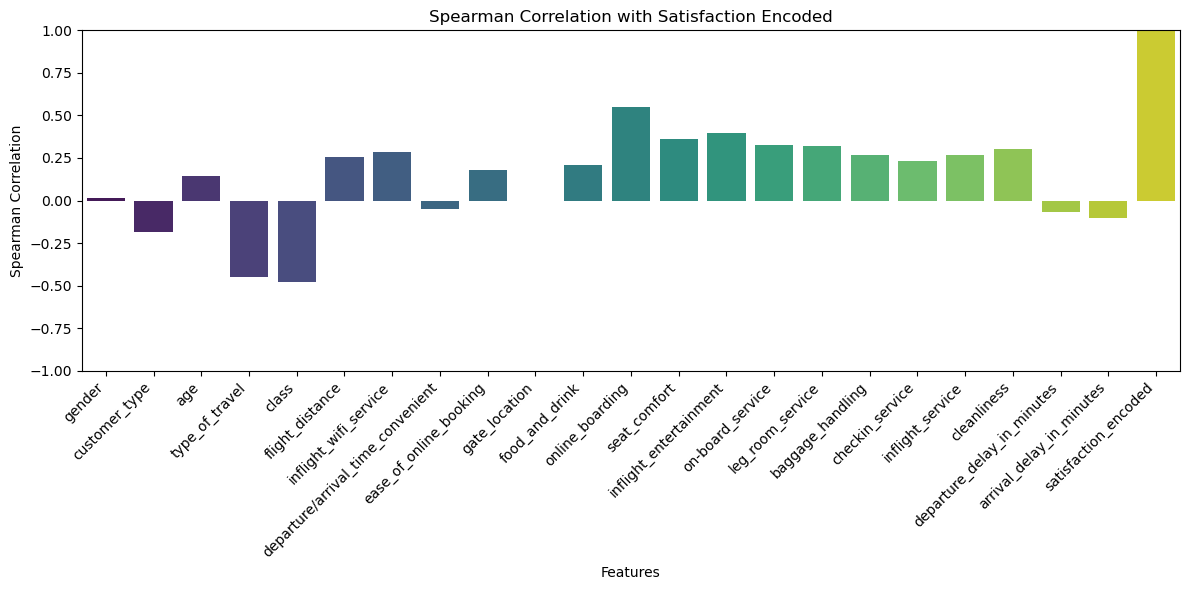

In [87]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.barplot(x=corr.index, y=corr.values, palette="viridis")
plt.title("Spearman Correlation with Satisfaction Encoded")
plt.xlabel("Features")
plt.ylabel("Spearman Correlation")
plt.xticks(rotation=45, ha="right")
plt.ylim(-1, 1)
plt.tight_layout()
plt.show()

# Model Selection


When choosing our models, we focused on ones known for their effectiveness in binary classification problems. We considered logistic regression, decision trees, random forest classifier, and k-nearest neighbors. To fine-tune our approach, we initially tested these models using only the features that showed the highest correlation with passenger satisfaction. Then, we ran the models again, this time testing all available features. Surprisingly, our results improved when we used the entire set of features, indicating the importance of using all features.


In [88]:
X_train = df_cleaned.drop("satisfaction_encoded", axis=1)
y_train = df_cleaned["satisfaction_encoded"]
X_test = df2_cleaned.drop("satisfaction_encoded", axis=1)
y_test = df2_cleaned["satisfaction_encoded"]

In [89]:
# Instantiate the classifiers

logreg_model = LogisticRegression(max_iter=10000)
dt_model = DecisionTreeClassifier(random_state=42)
rf_model = RandomForestClassifier(random_state=42)
knn_model = KNeighborsClassifier(n_neighbors=5)

In [90]:
# Train the models
logreg_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)

KNeighborsClassifier()

This code evaluates the performance of multiple classifiers on a test set. The classifiers include Logistic Regression, Decision Tree, Random Forest, and k-Nearest Neighbors (KNN). It prints the testing accuracy, precision, recall, and F1-score for each classifier.


In [91]:
classifiers = [
    ("Logistic Regression", logreg_model),
    ("Decision Tree", dt_model),
    ("Random Forest", rf_model),
    ("KNN", knn_model),
]
labels = ["Logistic Regression", "Decision Tree", "Random Forest", "KNN"]
reports = []
labels = []
precision = []
recall = []
f1_score = []
accuracy = []
for label, classifier in classifiers:
    y_pred = classifier.predict(X_test)
    accuracy_test = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)

    labels.append((label))
    precision.append(report["1"]["precision"])
    recall.append(report["1"]["recall"])
    f1_score.append(report["1"]["f1-score"])
    accuracy.append(accuracy_test)

    df_metrics = pd.DataFrame(
        {
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1_score,
            "Accuracy": accuracy,
        },
        index=labels,
    )
    print(label)
    print(f"Testing accuracy: {accuracy_test:.4f}")
    print("Classification Report (Testing Set):")
    print(classification_report(y_test, y_pred))

Logistic Regression
Testing accuracy: 0.8712
Classification Report (Testing Set):
              precision    recall  f1-score   support

           0       0.87      0.90      0.89     14528
           1       0.87      0.83      0.85     11365

    accuracy                           0.87     25893
   macro avg       0.87      0.87      0.87     25893
weighted avg       0.87      0.87      0.87     25893

Decision Tree
Testing accuracy: 0.9474
Classification Report (Testing Set):
              precision    recall  f1-score   support

           0       0.95      0.95      0.95     14528
           1       0.94      0.94      0.94     11365

    accuracy                           0.95     25893
   macro avg       0.95      0.95      0.95     25893
weighted avg       0.95      0.95      0.95     25893

Random Forest
Testing accuracy: 0.9630
Classification Report (Testing Set):
              precision    recall  f1-score   support

           0       0.96      0.98      0.97     14528
   

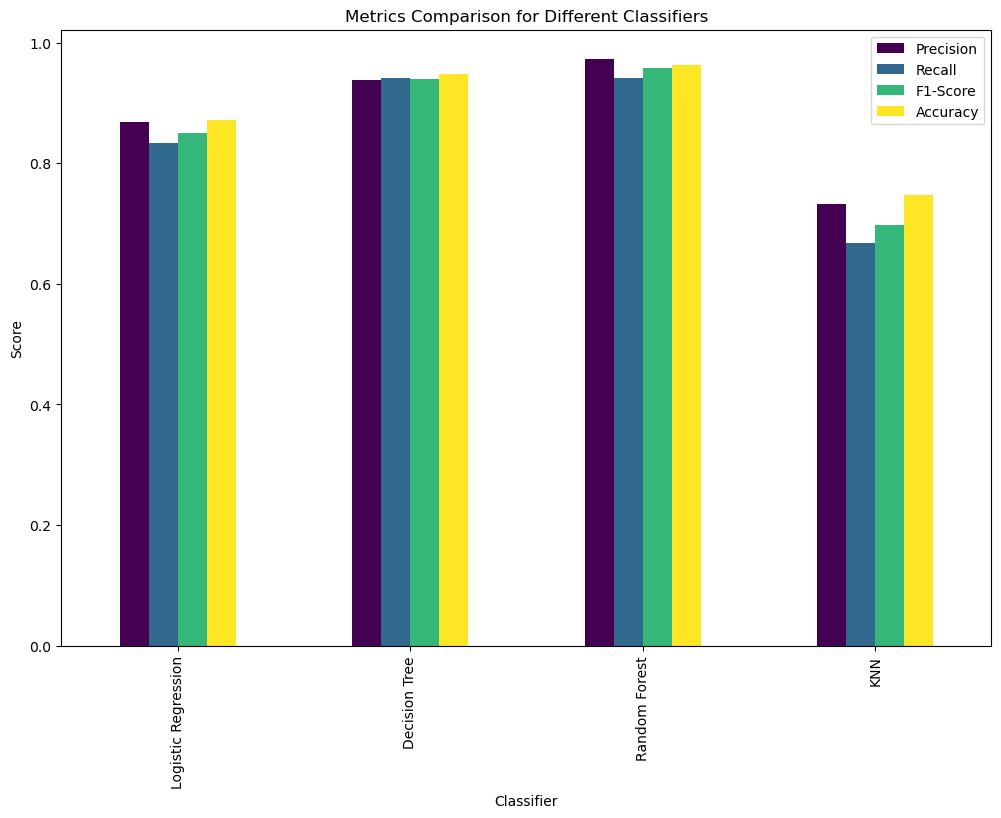

In [92]:
df_metrics.plot(kind="bar", colormap="viridis", figsize=(12, 8))
plt.title("Metrics Comparison for Different Classifiers")
plt.ylabel("Score")
plt.xlabel("Classifier")
plt.show()

# Random Forest Optimization

We will perform a random search optimization for our best model (Random Forest) during the test.


In [107]:
# different parameters we want to randomly try, these options were adjusted mltiple times for the best possible combinations
parameters_rf = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None],
    "min_samples_split": [2, 5, 10, 20, 30],
    "min_samples_leaf": [1, 2, 3],
}
rf_random_search = RandomizedSearchCV(
    RandomForestClassifier(),
    param_distributions=parameters_rf,
    n_iter=10,
    cv=5,
    scoring="accuracy",
    verbose=3,
)

In [108]:
rf_random_search.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV 1/5] END max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=500;, score=0.962 total time=  28.5s
[CV 2/5] END max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=500;, score=0.963 total time=  28.1s
[CV 3/5] END max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=500;, score=0.961 total time=  28.2s
[CV 4/5] END max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=500;, score=0.964 total time=  28.2s
[CV 5/5] END max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=500;, score=0.964 total time=  28.2s
[CV 1/5] END max_depth=None, min_samples_leaf=1, min_samples_split=10, n_estimators=200;, score=0.961 total time=  11.0s
[CV 2/5] END max_depth=None, min_samples_leaf=1, min_samples_split=10, n_estimators=200;, score=0.962 total time=  10.9s
[CV 3/5] END max_depth=None, min_samples_leaf=1, min_samples_split=10, n_estimators=200;, score=0

RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(),
                   param_distributions={'max_depth': [None],
                                        'min_samples_leaf': [1, 2, 3],
                                        'min_samples_split': [2, 5, 10, 20, 30],
                                        'n_estimators': [200, 300, 500]},
                   scoring='accuracy', verbose=3)

In [109]:
rf_best_model = rf_random_search.best_estimator_

In [110]:
rf_y_pred = rf_best_model.predict(X_test)

In [111]:
classifiers = [("Random Forest", rf_best_model)]

In [112]:
# Print or further analyze the results
print("Random Forest Best Parameters:", rf_random_search.best_params_)

Random Forest Best Parameters: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None}


Printing the metrics from optimization


In [113]:
labels = []
precision = []
recall = []
f1_score = []
accuracy = []

for label, classifier in classifiers:
    y_pred = classifier.predict(X_test)
    accuracy_test = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)

    labels.append(label)
    precision.append(report["1"]["precision"])
    recall.append(report["1"]["recall"])
    f1_score.append(report["1"]["f1-score"])
    accuracy.append(accuracy_test)

df_metrics = pd.DataFrame(
    {
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1_score,
        "Accuracy": accuracy,
    },
    index=labels,
)

In [114]:
# Print or further analyze the results
print("Random Forest Best Parameters:", rf_random_search.best_params_)
print("Metrics:")
print(df_metrics)

Random Forest Best Parameters: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None}
Metrics:
               Precision    Recall  F1-Score  Accuracy
Random Forest   0.972661  0.942279  0.957229   0.96304


# Simulation Code


In [115]:
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.metrics")

In [116]:
features_output = widgets.Output(
    layout={"border": "1px solid #ccc", "padding": "10px", "margin": "10px 0"}
)
predictions_output = widgets.Output(
    layout={"border": "1px solid #ccc", "padding": "10px", "margin": "10px 0"}
)

In [117]:
layout = widgets.VBox([features_output, predictions_output])

In [118]:
style_html = HTML(
    """
<style>
    .widget-label { font-weight: bold; }  /* Bold labels */
    .widget-description { color: #555; }  /* Dim description text */
</style>
"""
)
display(style_html)

In [119]:
display(layout)

This code simulates a real-time display of rows from our testing dataset along with predictions made by our Random Forest model. if the user decides to run the code feel free to change the simulation size and update timer for inputs since it can get lengthy


In [120]:
# we can adjust the input data set as well as the time it takes to update the next input
simulation_size = 20  # choose 20 rows for the simulation
sleep_timer = 1  # update every 1 second


def display_row(index):
    with features_output:
        clear_output(wait=True)
        # Display the features for the current row
        current_row = outputdf.iloc[index, :-1]
        current_row_predict = X_test.iloc[index]
        display(current_row)

    with predictions_output:
        clear_output(wait=True)
        current_values = current_row_predict.values.reshape(1, -1)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            rf_prediction = rf_model.predict(current_values)[0]
        if rf_prediction:
            print(f"Random Forest Prediction: Satisfied")
        else:
            print(f"Random Forest Prediction: Dissatisfied")


async def iterate_rows():
    global count
    for i in range(min(simulation_size, len(X_test))):
        if display_row(random.randint(0, len(X_test))):
            break
        await asyncio.sleep(sleep_timer)


await iterate_rows()

# Conclusion

In conclusion, our comprehensive analysis and experimentation with different machine learning models have yielded valuable insights. By utilizing all features in the dataset, we achieved a higher accuracy compared to a subset selected based on higher correlation.

Among the models tested:- Linear Regression, Decision Trees, K-Nearest Neighbors (KNN), and Random Forests, the Random Forest model emerged as the top performer with an impressive 96% accuracy. This performance made it the model of choice for further exploration and optimization.

Through hyperparameter tuning, we fine-tuned the Random Forest model using a Randomized search cross validation with 10 iterationas and 5 folds with a total of 50 fits. This resulted in a subtle boost in accuracy ~, demonstrating the impact of parameter optimization on model performance

We then decided to build a simple simulation that showcases how the model would operate in the real world by grabbing data from the testing set and and feed it to the model in order to get a prediction.

In summary, our comprehensive approach from feature selection and model comparison to hyperparameter tuning and real-time simulation has empowered us to develop a highly accurate and versatile predictive model thanks to the the success of the Random Forest algorithm in addressing our specific task.


# Appendix

Sample output of the simulation, showing the prediction of our model based on the input from the testing set, the original satisfsction was included to show how our model performs


![Alt Text](sample_output_1.png)


![Alt Text](sample_output_2.png)


![Alt Text](sample_output_3.png)
